# Praktikum Klasifikasi Organisme Laut (Oceanic Life) Menggunakan CNN

In [2]:
import os
import sys
import json
import pickle
import shutil
import hashlib
import warnings
from pathlib import Path
from collections import Counter

try:
    from IPython.display import display
except Exception:
    def display(*args, **kwargs):
        for a in args:
            print(a)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# Nonaktifkan pemuatan gambar terpotong agar terdeteksi secara ketat saat validasi
ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.filterwarnings("ignore")

# Set random seed untuk reprodusibilitas
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Folder penyimpanan artefak untuk Streamlit (Langkah 7)
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"TensorFlow Version : {tf.__version__}")
print(f"GPU Available      : {tf.config.list_physical_devices('GPU')}")
print(f"Artifacts Folder   : {ARTIFACTS_DIR.resolve()}")

TensorFlow Version : 2.21.0
GPU Available      : []
Artifacts Folder   : C:\test 2 Klasifikasi CNN\artifacts


<h3>Langkah 1 — Pengambilan dan Pemahaman Dataset</h3>

In [3]:
# 8 Kelas Organisme Laut utama (target klasifikasi CNN)
CANDIDATE_CLASSES = [
    "coral", "crab", "fish", "octopus", "seal", "shark", "starfish", "turtle"
]
# Organisme laut lain: CLIP ikut menilainya, lalu seluruhnya DIGABUNG menjadi satu kelas "other"
# agar tidak dipaksa masuk ke 8 kelas utama dan tidak ada gambar yang dibuang.
# (Kosongkan list ini jika ingin semua gambar dipaksa masuk ke 8 kelas utama saja.)
OTHER_CLASSES = ["dolphin", "eel", "jellyfish", "ray", "seahorse", "shrimp", "whale"]
OTHER_LABEL = "other"

# Folder keluaran notebook TIDAK boleh terbaca sebagai dataset mentah (mencegah gambar terhitung ganda)
EXCLUDE_DIRS = {"artifacts", "dataset_structured", "dataset_structured_15kelas", "dataset_structured_8kelas", "dataset_structured_9kelas", ".ipynb_checkpoints", "__pycache__"}

# Isi manual jika folder dataset mentah tidak ditemukan otomatis, contoh: Path("/path/ke/OceanicLife Dataset")
RAW_DATA_DIR_OVERRIDE = None

DATASET_CANDIDATE_PATHS = [
    Path("C:\test 2 Klasifikasi CNN"),
    Path("OceanicLife Dataset"),
    Path("dataset"),
    Path("oceanic_life"),
    Path("data"),
    Path("../input"),
]

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tiff"}

def is_raw_image(p, root):
    """True jika p adalah file gambar di bawah root dan tidak berada di folder keluaran notebook."""
    if not (p.is_file() and p.suffix.lower() in IMAGE_EXTS):
        return False
    return not (set(p.relative_to(root).parts[:-1]) & EXCLUDE_DIRS)

def has_images(root):
    return root.exists() and any(is_raw_image(f, root) for f in root.rglob("*"))

def locate_or_download_dataset(kaggle_slug="msahebi/oceanic-life"):
    if RAW_DATA_DIR_OVERRIDE is not None:
        p = Path(RAW_DATA_DIR_OVERRIDE)
        if has_images(p):
            print(f"[INFO] Dataset (manual) ditemukan di: {p.resolve()}")
            return p
        raise FileNotFoundError(f"RAW_DATA_DIR_OVERRIDE tidak berisi gambar: {p}")
    for p in DATASET_CANDIDATE_PATHS:
        if has_images(p):
            print(f"[INFO] Dataset ditemukan di direktori lokal: {p.resolve()}")
            return p
    try:
        import importlib
        kagglehub = importlib.import_module("kagglehub")
        print(f"[INFO] Mengunduh dataset '{kaggle_slug}' dari Kaggle...")
        dl_path = Path(kagglehub.dataset_download(kaggle_slug))
        print(f"[INFO] Dataset berhasil diunduh ke: {dl_path}")
        return dl_path
    except Exception as e:
        raise FileNotFoundError(
            "Dataset mentah tidak ditemukan. Letakkan folder dataset di samping notebook "
            "atau isi RAW_DATA_DIR_OVERRIDE di sel ini. Detail: " + str(e)
        )

RAW_DATA_DIR = locate_or_download_dataset()

# Pelajari struktur folder dataset mentah
all_files = [p for p in RAW_DATA_DIR.rglob("*") if is_raw_image(p, RAW_DATA_DIR)]

subfolders_with_images = sorted({p.parent for p in all_files if p.parent != RAW_DATA_DIR})
print("=" * 65)
print("RINGKASAN STRUKTUR FOLDER DATASET MENTAH")
print("=" * 65)
print(f"Lokasi Root Dataset      : {RAW_DATA_DIR.resolve()}")
print(f"Total File Gambar Mentah : {len(all_files)} file")
print(f"Jumlah Subfolder Gambar  : {len(subfolders_with_images)} subfolder")
if subfolders_with_images[:10]:
    print("Contoh Subfolder         :", [sf.name for sf in subfolders_with_images[:10]])
print("Catatan                  : dataset mentah tidak memiliki folder kelas -> pelabelan otomatis CLIP zero-shot")


[INFO] Dataset ditemukan di direktori lokal: C:\test 2 Klasifikasi CNN\OceanicLife Dataset
RINGKASAN STRUKTUR FOLDER DATASET MENTAH
Lokasi Root Dataset      : C:\test 2 Klasifikasi CNN\OceanicLife Dataset
Total File Gambar Mentah : 7960 file
Jumlah Subfolder Gambar  : 0 subfolder
Catatan                  : dataset mentah tidak memiliki folder kelas -> pelabelan otomatis CLIP zero-shot


In [4]:
# Validasi file gambar 
valid_images = []
corrupt_files = []
duplicate_files = []
seen_hashes = set()

for img_path in all_files:
    try:
        # Verifikasi penuh header dan seluruh scanline piksel gambar
        with Image.open(img_path) as im:
            im.verify()
        with Image.open(img_path) as im:
            im.load()
        file_bytes = img_path.read_bytes()
        file_hash = hashlib.md5(file_bytes).hexdigest()
        if file_hash in seen_hashes:
            duplicate_files.append(img_path)
        else:
            seen_hashes.add(file_hash)
            valid_images.append(img_path)
    except Exception:
        corrupt_files.append(img_path)

print(f"Total Gambar Mentah      : {len(all_files)}")
print(f"Gambar Rusak (Corrupt)   : {len(corrupt_files)}")
print(f"Gambar Duplikat (MD5)    : {len(duplicate_files)}")
print(f"Gambar Unik & Valid      : {len(valid_images)}")

Total Gambar Mentah      : 7960
Gambar Rusak (Corrupt)   : 8
Gambar Duplikat (MD5)    : 6930
Gambar Unik & Valid      : 1022


In [5]:
# Penentuan Label Kelas: Zero-Shot Pseudo-Labeling CLIP (dataset mentah tidak memiliki folder kelas)
# Prasyarat (sekali saja): pip install torch transformers   |  unduhan awal model CLIP butuh internet (~600 MB)
import torch
from transformers import CLIPProcessor, CLIPModel

LABEL_MODE = "zeroshot"
CONF_THRESHOLD = 0.35       # 0.0 = pakai semua gambar. Naikkan (mis. 0.35) untuk membuang gambar berlabel meragukan
MIN_IMAGES_PER_CLASS = 10    # kelas dengan gambar lebih sedikit dikeluarkan (tidak bisa dibagi 80:20 secara stratified)
CLIP_BATCH = 16

# Deskripsi teks tiap kelas (lebih deskriptif = zero-shot lebih akurat)
CLASS_PROMPT_NAMES = {
    "coral": "coral", "crab": "a crab", "dolphin": "a dolphin", "eel": "an eel", "fish": "a fish",
    "jellyfish": "a jellyfish", "octopus": "an octopus", "ray": "a stingray or manta ray",
    "seahorse": "a seahorse", "seal": "a seal or sea lion", "shark": "a shark", "shrimp": "a shrimp",
    "starfish": "a starfish", "turtle": "a sea turtle", "whale": "a whale",
}
PROMPT_TEMPLATES = ["a photo of {}.", "an underwater photo of {}.", "a close-up photo of {}.", "a nature photograph of {}."]

N_TARGET = len(CANDIDATE_CLASSES)
ALL_CLIP_CLASSES = CANDIDATE_CLASSES + OTHER_CLASSES        # 8 kelas utama + organisme lain
FINAL_LABELS = CANDIDATE_CLASSES + [OTHER_LABEL]            # label akhir: 8 kelas utama + "other"
prompts = [t.format(CLASS_PROMPT_NAMES[c]) for c in ALL_CLIP_CLASSES for t in PROMPT_TEMPLATES]  # urut per kelas
NUM_CAND = len(ALL_CLIP_CLASSES)

device = "cuda" if torch.cuda.is_available() else "cpu"
clip_model_name = "openai/clip-vit-base-patch32"
print(f"[INFO] Zero-Shot Pseudo-Labeling dengan {clip_model_name}: {N_TARGET} kelas utama + {len(OTHER_CLASSES)} organisme lain -> kelas '{OTHER_LABEL}' (device: {device})...")
clip_model = CLIPModel.from_pretrained(clip_model_name).to(device).eval()
clip_processor = CLIPProcessor.from_pretrained(clip_model_name)

records = []
for i in range(0, len(valid_images), CLIP_BATCH):
    batch_paths = valid_images[i : i + CLIP_BATCH]
    pil_imgs, ok_paths = [], []
    for p in batch_paths:
        try:
            with Image.open(p) as im:
                pil_imgs.append(im.convert("RGB"))
            ok_paths.append(p)
        except Exception:
            pass
    if not pil_imgs:
        continue
    inputs = clip_processor(text=prompts, images=pil_imgs, return_tensors="pt", padding=True).to(device)
    with torch.no_grad():
        out = clip_model(**inputs)
    # rata-rata skor dari semua template per kelas (prompt ensembling), lalu softmax antar semua kelas CLIP
    logits = out.logits_per_image.reshape(len(pil_imgs), NUM_CAND, len(PROMPT_TEMPLATES)).mean(dim=2)
    probs = logits.softmax(dim=1).cpu().numpy()                                    # [B, 8 + organisme lain]
    # gabungkan seluruh peluang organisme lain menjadi satu kelas "other"
    merged = np.concatenate([probs[:, :N_TARGET], probs[:, N_TARGET:].sum(axis=1, keepdims=True)], axis=1)   # [B, 9]
    for p, pv, raw in zip(ok_paths, merged, probs):
        top = int(np.argmax(pv))
        records.append({
            "filepath": str(p),
            "label": FINAL_LABELS[top],
            "confidence": float(pv[top]),
            "clip_detail": ALL_CLIP_CLASSES[int(np.argmax(raw))],   # kelas CLIP asli (untuk melihat isi kelas "other")
        })
    if (i // CLIP_BATCH) % 20 == 0:
        print(f"   ... {min(i + CLIP_BATCH, len(valid_images))}/{len(valid_images)} gambar diproses")

df_all = pd.DataFrame(records)
df_all.to_csv(ARTIFACTS_DIR / "pseudo_label_clip.csv", index=False)   # arsip label otomatis untuk diperiksa

# Saring label meragukan (opsional) dan kelas yang terlalu kecil
df_data = df_all[df_all["confidence"] >= CONF_THRESHOLD].copy()
N_LOW_CONF = int(len(df_all) - len(df_data))
cnt_tmp = df_data["label"].value_counts()
SMALL_CLASSES_DROPPED = cnt_tmp[cnt_tmp < MIN_IMAGES_PER_CLASS].index.tolist()
if SMALL_CLASSES_DROPPED:
    df_data = df_data[~df_data["label"].isin(SMALL_CLASSES_DROPPED)]
df_data = df_data.reset_index(drop=True)
N_OTHER = int((df_data["label"] == OTHER_LABEL).sum())

CLASS_NAMES = sorted(df_data["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)

print(f"\n[INFO] Gambar diberi label CLIP          : {len(df_all)}")
print(f"[INFO] Dibuang (keyakinan < {CONF_THRESHOLD:.2f})      : {N_LOW_CONF}")
print(f"[INFO] Kelas dikeluarkan (< {MIN_IMAGES_PER_CLASS} gambar)    : {SMALL_CLASSES_DROPPED if SMALL_CLASSES_DROPPED else 'tidak ada'}")
print(f"[INFO] Isi kelas '{OTHER_LABEL}' ({N_OTHER} gambar)   : {df_data[df_data['label'] == OTHER_LABEL]['clip_detail'].value_counts().to_dict()}")
print(f"[SUKSES] Dataset siap digunakan! Jumlah kelas: {NUM_CLASSES} kelas | Total gambar bersih: {len(df_data)}")
print(f"Daftar {NUM_CLASSES} Kelas:", CLASS_NAMES)
if NUM_CLASSES < 2:
    raise RuntimeError("Kurang dari 2 kelas tersisa. Periksa dataset.")
display(
    df_data.groupby("label")["confidence"].agg(**{"Jumlah Gambar": "count", "Rata-rata Keyakinan CLIP": "mean"})
    .sort_values("Jumlah Gambar", ascending=False).round(3).rename_axis("Kelas").reset_index()
)


[INFO] Zero-Shot Pseudo-Labeling dengan openai/clip-vit-base-patch32: 8 kelas utama + 7 organisme lain -> kelas 'other' (device: cpu)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

   ... 16/1022 gambar diproses
   ... 336/1022 gambar diproses
   ... 656/1022 gambar diproses
   ... 976/1022 gambar diproses

[INFO] Gambar diberi label CLIP          : 1022
[INFO] Dibuang (keyakinan < 0.35)      : 15
[INFO] Kelas dikeluarkan (< 10 gambar)    : tidak ada
[INFO] Isi kelas 'other' (318 gambar)   : {'ray': 82, 'seahorse': 46, 'jellyfish': 34, 'eel': 34, 'shrimp': 33, 'whale': 33, 'dolphin': 32, 'fish': 15, 'shark': 4, 'coral': 3, 'crab': 1, 'octopus': 1}
[SUKSES] Dataset siap digunakan! Jumlah kelas: 9 kelas | Total gambar bersih: 1007
Daftar 9 Kelas: ['coral', 'crab', 'fish', 'octopus', 'other', 'seal', 'shark', 'starfish', 'turtle']


,Kelas,Jumlah Gambar,Rata-rata Keyakinan CLIP
0,other,318,0.844
1,fish,257,0.836
2,coral,144,0.777
3,seal,69,0.979
4,crab,59,0.838
5,shark,55,0.839
6,turtle,37,0.973
7,octopus,35,0.896
8,starfish,33,0.962


<h3>Langkah 2 — Eksplorasi Data (Exploratory Data Analysis / EDA)</h3>

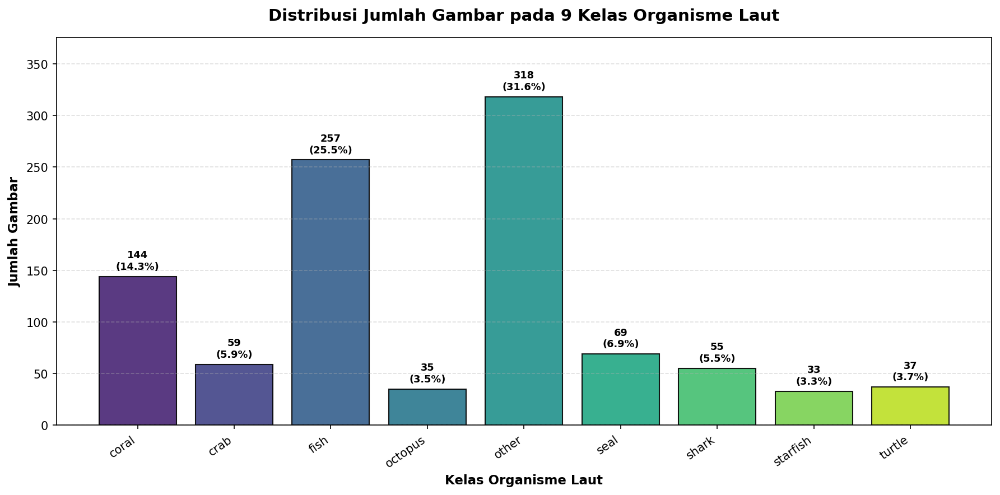

IDENTIFIKASI KETIDAKSEIMBANGAN DATA (CLASS IMBALANCE)
Kelas Terbanyak          : other (318 gambar / 31.6%)
Kelas Tersedikit         : starfish (33 gambar / 3.3%)
Rasio Ketidakseimbangan  : 9.64:1
Status Class Imbalance   : TERDAPAT CLASS IMBALANCE (Rasio > 1.5:1)
Solusi Mitigasi          : Menggunakan Stratified Split + Class Weighting + Data Augmentation.


In [6]:
# 2.1 Hitung & Visualisasikan Distribusi Jumlah Gambar per Kelas
class_counts = df_data["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
total_clean = len(df_data)

fig, ax = plt.subplots(figsize=(12, 6), dpi=150)
colors = sns.color_palette("viridis", len(CLASS_NAMES))
bars = ax.bar(class_counts.index, class_counts.values, color=colors, edgecolor="black", alpha=0.9)

for bar in bars:
    h = bar.get_height()
    pct = (h / total_clean) * 100 if total_clean > 0 else 0
    ax.text(
        bar.get_x() + bar.get_width() / 2, h + max(class_counts.values) * 0.015,
        f"{int(h)}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=8.5, fontweight="bold"
    )

ax.set_title(f"Distribusi Jumlah Gambar pada {NUM_CLASSES} Kelas Organisme Laut", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Kelas Organisme Laut", fontsize=11, fontweight="bold")
ax.set_ylabel("Jumlah Gambar", fontsize=11, fontweight="bold")
ax.set_ylim(0, max(class_counts.values) * 1.18 if len(class_counts) else 10)
plt.xticks(rotation=35, ha="right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "distribusi_kelas.png", dpi=150)
plt.show()

# Identifikasi Class Imbalance
max_cls, max_val = class_counts.idxmax(), int(class_counts.max())
min_cls, min_val = class_counts.idxmin(), int(class_counts.min())
imbalance_ratio = round(max_val / max(min_val, 1), 2)
is_imbalanced = imbalance_ratio > 1.5

print("=" * 65)
print("IDENTIFIKASI KETIDAKSEIMBANGAN DATA (CLASS IMBALANCE)")
print("=" * 65)
print(f"Kelas Terbanyak          : {max_cls} ({max_val} gambar / {max_val/total_clean*100:.1f}%)")
print(f"Kelas Tersedikit         : {min_cls} ({min_val} gambar / {min_val/total_clean*100:.1f}%)")
print(f"Rasio Ketidakseimbangan  : {imbalance_ratio}:1")
print(f"Status Class Imbalance   : {'TERDAPAT CLASS IMBALANCE (Rasio > 1.5:1)' if is_imbalanced else 'SEIMBANG'}")
if is_imbalanced:
    print("Solusi Mitigasi          : Menggunakan Stratified Split + Class Weighting + Data Augmentation.")

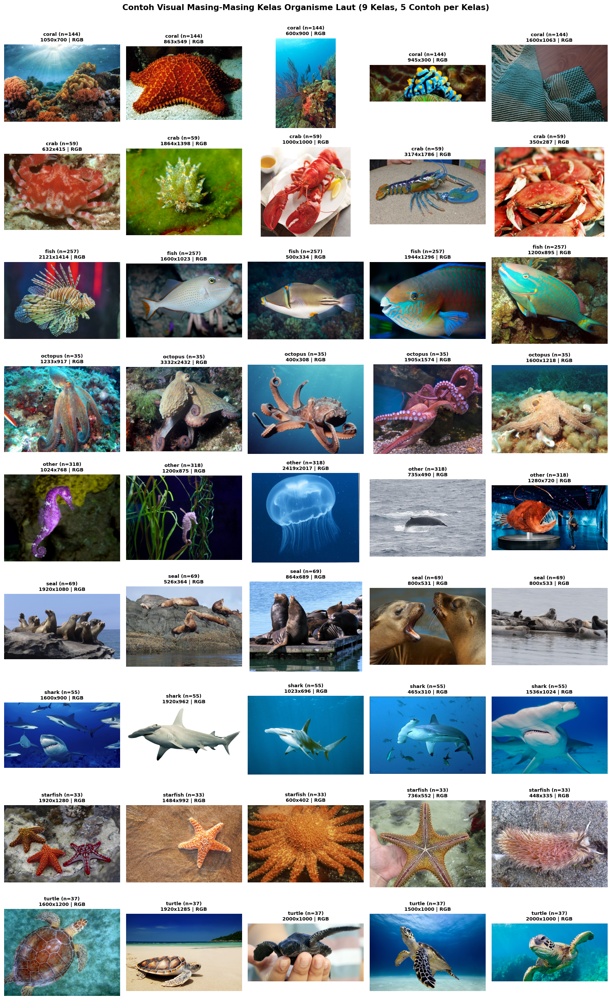

In [7]:
# 2.2 Visualisasi Beberapa Contoh Gambar dari Setiap Kelas (Semua Kelas)
N_PER_CLASS = 5   # jumlah contoh gambar per kelas (satu baris = satu kelas)
fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(3 * N_PER_CLASS, 2.7 * NUM_CLASSES), dpi=110)
axes = np.atleast_2d(axes)

for r, cls_name in enumerate(CLASS_NAMES):
    subset = df_data[df_data["label"] == cls_name]
    picks = subset.sample(n=min(N_PER_CLASS, len(subset)), random_state=SEED)
    for c in range(N_PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(picks):
            with Image.open(picks.iloc[c]["filepath"]) as im:
                w, h = im.size
                mode = im.mode
                ax.imshow(im.convert("RGB"))
            ax.set_title(f"{cls_name} (n={len(subset)})\n{w}x{h} | {mode}", fontsize=8.5, fontweight="bold")

plt.suptitle(f"Contoh Visual Masing-Masing Kelas Organisme Laut ({NUM_CLASSES} Kelas, {N_PER_CLASS} Contoh per Kelas)",
             fontsize=14, fontweight="bold", y=1.002)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "contoh_gambar.png", dpi=110, bbox_inches="tight")
plt.show()


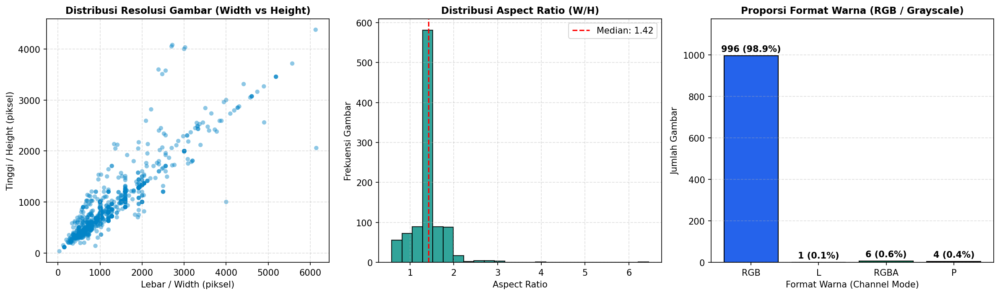

RINGKASAN ANALISIS UKURAN, FORMAT WARNA, DAN KUALITAS GAMBAR
Rentang Lebar (Width)    : 32 px – 6144 px (Rata-rata: 1227.6 px)
Rentang Tinggi (Height)  : 32 px – 4378 px (Rata-rata: 895.0 px)
Distribusi Format Warna  : {'RGB': 996, 'L': 1, 'RGBA': 6, 'P': 4}
Kondisi Kualitas Gambar  : 1022 gambar valid & tajam, 8 file rusak telah dihapus, 6930 duplikat dihapus.


In [8]:
# 2.3 Analisis Ukuran Gambar (Resolusi), Format Warna (RGB/Grayscale), dan Kualitas Gambar
widths, heights, aspect_ratios, color_modes = [], [], [], []

for fp in df_data["filepath"]:
    try:
        with Image.open(fp) as im:
            w, h = im.size
            widths.append(w)
            heights.append(h)
            aspect_ratios.append(round(w / max(h, 1), 2))
            color_modes.append(im.mode)
    except Exception:
        pass

mode_counts = Counter(color_modes)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150)

# Plot 1: Scatter Lebar vs Tinggi
axes[0].scatter(widths, heights, alpha=0.45, c="#0284c7", edgecolors="none", s=25)
axes[0].set_title("Distribusi Resolusi Gambar (Width vs Height)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Lebar / Width (piksel)")
axes[0].set_ylabel("Tinggi / Height (piksel)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Plot 2: Histogram Aspect Ratio
axes[1].hist(aspect_ratios, bins=25, color="#0d9488", edgecolor="black", alpha=0.85)
axes[1].axvline(np.median(aspect_ratios), color="red", linestyle="--", label=f"Median: {np.median(aspect_ratios):.2f}")
axes[1].set_title("Distribusi Aspect Ratio (W/H)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Aspect Ratio")
axes[1].set_ylabel("Frekuensi Gambar")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

# Plot 3: Format Warna (RGB vs Grayscale/RGBA)
axes[2].bar(list(mode_counts.keys()), list(mode_counts.values()), color=["#2563eb", "#f59e0b", "#10b981"][:len(mode_counts)], edgecolor="black")
for i, (k, v) in enumerate(mode_counts.items()):
    axes[2].text(i, v + max(mode_counts.values()) * 0.02, f"{v} ({v/len(color_modes)*100:.1f}%)", ha="center", fontweight="bold")
axes[2].set_title("Proporsi Format Warna (RGB / Grayscale)", fontsize=11, fontweight="bold")
axes[2].set_xlabel("Format Warna (Channel Mode)")
axes[2].set_ylabel("Jumlah Gambar")
axes[2].set_ylim(0, max(mode_counts.values()) * 1.18)
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "ukuran_gambar.png", dpi=150)
plt.show()

print("=" * 65)
print("RINGKASAN ANALISIS UKURAN, FORMAT WARNA, DAN KUALITAS GAMBAR")
print("=" * 65)
print(f"Rentang Lebar (Width)    : {min(widths)} px – {max(widths)} px (Rata-rata: {np.mean(widths):.1f} px)")
print(f"Rentang Tinggi (Height)  : {min(heights)} px – {max(heights)} px (Rata-rata: {np.mean(heights):.1f} px)")
print(f"Distribusi Format Warna  : {dict(mode_counts)}")
print(f"Kondisi Kualitas Gambar  : {len(valid_images)} gambar valid & tajam, {len(corrupt_files)} file rusak telah dihapus, {len(duplicate_files)} duplikat dihapus.")

<h3>Langkah 3 — Pra-Pemrosesan Data</h3>

In [9]:
# 3.1 Konfigurasi Ukuran Gambar & Encoding Label (Numerik + One-Hot Encoding)
IMG_SIZE = 160  # Ukuran seragam (dapat diubah ke 48 jika ingin 48x48 piksel)
CHANNELS = 3    # Konversi seragam ke RGB (3 channel)

class_to_idx = {cls_name: i for i, cls_name in enumerate(CLASS_NAMES)}
idx_to_class = {i: cls_name for i, cls_name in enumerate(CLASS_NAMES)}

df_data["label_idx"] = df_data["label"].map(class_to_idx)

# 3.2 Pembagian Dataset: 80% Training Set & 20% Validation/Test Set (Stratified)
train_df, val_test_df = train_test_split(
    df_data,
    test_size=0.20,          # Tepat 20% untuk Validation/Test Set sesuai instruksi dosen
    random_state=SEED,
    stratify=df_data["label_idx"]
)

# Sesuai instruksi dosen, 20% data berfungsi sebagai SATU Validation/Test Set (val_df dan test_df berisi data yang sama).
# Data ini tidak dipakai untuk memperbarui bobot model, tetapi dipakai untuk EarlyStopping dan evaluasi akhir.
val_df = val_test_df.copy().reset_index(drop=True)
test_df = val_test_df.copy().reset_index(drop=True)
train_df = train_df.reset_index(drop=True)

# One-Hot Encoding untuk label Training dan Validation/Test
y_train_num = train_df["label_idx"].values
y_test_num = test_df["label_idx"].values

y_train_onehot = tf.keras.utils.to_categorical(y_train_num, num_classes=NUM_CLASSES)
y_test_onehot = tf.keras.utils.to_categorical(y_test_num, num_classes=NUM_CLASSES)

print("=" * 65)
print("HASIL PRA-PEMROSESAN & PEMBAGIAN DATASET (80% TRAIN : 20% VAL/TEST)")
print("=" * 65)
print(f"Ukuran Gambar Seragam    : {IMG_SIZE}x{IMG_SIZE} piksel ({CHANNELS} channel RGB)")
print(f"Rentang Normalisasi      : 0.0 – 1.0 (Rescaling 1./255)")
print(f"Training Set (80%)       : {len(train_df)} gambar ({len(train_df)/len(df_data)*100:.1f}%)")
print(f"Validation/Test Set (20%): {len(test_df)} gambar ({len(test_df)/len(df_data)*100:.1f}%)")
print(f"Contoh Label Numerik     : {y_train_num[:5]} -> One-Hot Shape: {y_train_onehot.shape}")

HASIL PRA-PEMROSESAN & PEMBAGIAN DATASET (80% TRAIN : 20% VAL/TEST)
Ukuran Gambar Seragam    : 160x160 piksel (3 channel RGB)
Rentang Normalisasi      : 0.0 – 1.0 (Rescaling 1./255)
Training Set (80%)       : 805 gambar (79.9%)
Validation/Test Set (20%): 202 gambar (20.1%)
Contoh Label Numerik     : [4 2 2 6 2] -> One-Hot Shape: (805, 9)


In [10]:
# Opsional: Menyusun fisik file ke struktur folder dataset_structured_9kelas/{train,test}/<nama_kelas>
# agar struktur direktori terlihat rapi saat diperiksa dosen (Langkah 1 & Langkah 3)
STRUCTURED_DIR = Path("dataset_structured_9kelas")
for split_name, split_frame in [("train", train_df), ("test", test_df)]:
    for _, row in split_frame.iterrows():
        target_folder = STRUCTURED_DIR / split_name / row["label"]
        target_folder.mkdir(parents=True, exist_ok=True)
        src_path = Path(row["filepath"])
        dst_path = target_folder / src_path.name
        if not dst_path.exists():
            try:
                shutil.copy2(src_path, dst_path)
            except Exception:
                pass

print(f"[INFO] Struktur folder dataset berhasil disusun di: {STRUCTURED_DIR.resolve()}")
print("Subfolder di dalamnya:", [p.name for p in STRUCTURED_DIR.iterdir() if p.is_dir()])

[INFO] Struktur folder dataset berhasil disusun di: C:\test 2 Klasifikasi CNN\dataset_structured_9kelas
Subfolder di dalamnya: ['test', 'train']


In [11]:
# 3.3 Pipeline Data TensorFlow (Resize, Normalisasi 0-1, One-Hot Label) & Data Augmentation
BATCH_SIZE = 32

# Layer Data Augmentation (Rotasi, Flipping, Zoom, dan Shift/Translation)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(height_factor=0.10, width_factor=0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

# Simpan visualisasi contoh hasil augmentasi untuk dashboard Streamlit (Langkah 3 & 7)
if len(train_df) > 0:
    try:
        sample_aug_img_path = train_df.iloc[0]["filepath"]
        with Image.open(sample_aug_img_path) as im:
            sample_aug_arr = np.array(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32) / 255.0
        fig, axes = plt.subplots(1, 5, figsize=(15, 3.5), dpi=150)
        axes[0].imshow(sample_aug_arr)
        axes[0].set_title("Gambar Asli", fontsize=10, fontweight="bold")
        axes[0].axis("off")
        for i in range(1, 5):
            aug_tensor = data_augmentation(tf.expand_dims(sample_aug_arr, axis=0), training=True)[0].numpy()
            aug_tensor = np.clip(aug_tensor, 0.0, 1.0)
            axes[i].imshow(aug_tensor)
            axes[i].set_title(f"Augmentasi {i}", fontsize=10, fontweight="bold")
            axes[i].axis("off")
        plt.suptitle("Contoh Penerapan Data Augmentation (Rotasi, Flip, Zoom, Translation)", fontsize=12, fontweight="bold", y=1.02)
        plt.tight_layout()
        plt.savefig(ARTIFACTS_DIR / "augmentasi.png", dpi=150, bbox_inches="tight")
        plt.close(fig)
    except Exception as e:
        print(f"[PERINGATAN] Gagal menyimpan augmentasi.png: {e}")

def load_and_preprocess_image(filepath, onehot_label):
    img_bytes = tf.io.read_file(filepath)
    img = tf.image.decode_image(img_bytes, channels=CHANNELS, expand_animations=False)
    img.set_shape([None, None, CHANNELS])
    # Resize ke ukuran seragam (IMG_SIZE x IMG_SIZE)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    # Normalisasi nilai piksel ke rentang 0 - 1
    img = tf.cast(img, tf.float32) / 255.0
    return img, onehot_label

def make_dataset(df_subset, onehot_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df_subset["filepath"].values, onehot_labels))
    if training:
        ds = ds.shuffle(buffer_size=len(df_subset), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(
            lambda x, y: (data_augmentation(x, training=True), y),
            num_parallel_calls=tf.data.AUTOTUNE
        )
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_df, y_train_onehot, training=True)
val_ds = make_dataset(val_df, y_test_onehot, training=False)
test_ds = make_dataset(test_df, y_test_onehot, training=False)

# Hitung Class Weight untuk menyeimbangkan kontribusi kelas minoritas saat training
class_weights_arr = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASSES),
    y=y_train_num
)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights_arr)}
print(f"Class Weights ({NUM_CLASSES} Kelas):", {CLASS_NAMES[i]: round(w, 2) for i, w in class_weight_dict.items()})

Class Weights (9 Kelas): {'coral': 0.78, 'crab': 1.9, 'fish': 0.43, 'octopus': 3.19, 'other': 0.35, 'seal': 1.63, 'shark': 2.03, 'starfish': 3.44, 'turtle': 2.98}


<h3>Langkah 4 — Pembangunan Model CNN</h3>

In [12]:
# Parameter Model CNN (Sesuai Langkah 4)
ARCH_MODE = "hybrid_mobilenetv2"  # Pilihan: "hybrid_mobilenetv2" atau "custom_cnn"
OPTIMIZER_NAME = "Adam"           # Pilihan: "Adam" atau "RMSprop"
LEARNING_RATE = 1e-3
FINE_TUNE_LR = 2e-5
EPOCHS_PHASE_1 = 10
EPOCHS_PHASE_2 = 7
TOTAL_EPOCHS = EPOCHS_PHASE_1 + EPOCHS_PHASE_2
DENSE_NEURONS = 256

def get_optimizer(name, lr):
    if name.lower() == "rmsprop":
        return optimizers.RMSprop(learning_rate=lr)
    return optimizers.Adam(learning_rate=lr)

def build_custom_cnn(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS), num_classes=NUM_CLASSES):
    """Arsitektur CNN Murni: 4 Lapisan Convolution + ReLU, MaxPooling2D, Flatten, Fully Connected ReLU, Output Softmax."""
    model = models.Sequential([
        layers.Input(shape=input_shape, name="input_image"),
        # Blok Konvolusi 1 (32 neuron/filter)
        layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv2d_1"),
        layers.BatchNormalization(name="bn_1"),
        layers.MaxPooling2D((2, 2), name="maxpool_1"),
        # Blok Konvolusi 2 (64 neuron/filter)
        layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2d_2"),
        layers.BatchNormalization(name="bn_2"),
        layers.MaxPooling2D((2, 2), name="maxpool_2"),
        # Blok Konvolusi 3 (128 neuron/filter)
        layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv2d_3"),
        layers.BatchNormalization(name="bn_3"),
        layers.MaxPooling2D((2, 2), name="maxpool_3"),
        # Blok Konvolusi 4 (256 neuron/filter) - Diberi nama 'out_relu' untuk kompatibilitas Grad-CAM di app.py
        layers.Conv2D(256, (3, 3), padding="same", activation="relu", name="out_relu"),
        layers.BatchNormalization(name="bn_4"),
        layers.MaxPooling2D((2, 2), name="maxpool_4"),
        # Flatten & Fully Connected Layers
        layers.Flatten(name="flatten"),
        layers.Dense(DENSE_NEURONS, activation="relu", name="fc_hidden_relu"),
        layers.Dropout(0.4, name="dropout"),
        layers.Dense(num_classes, activation="softmax", name="output_softmax")
    ], name="CNN_OceanicLife_Custom")
    return model, None

def build_hybrid_cnn(input_shape=(IMG_SIZE, IMG_SIZE, CHANNELS), num_classes=NUM_CLASSES):
    """Arsitektur CNN Berbasis MobileNetV2 (Convolutional Backbone) + Pooling + Fully Connected ReLU + Output Softmax."""
    inputs = layers.Input(shape=input_shape, name="input_image")
    # MobileNetV2 mengharapkan piksel [-1, 1]; ubah dari [0, 1] ke [-1, 1]
    x = layers.Rescaling(2.0, offset=-1.0, name="mobilenet_rescaling")(inputs)
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=input_shape, include_top=False, weights="imagenet"
    )
    base_model.trainable = False
    conv_features = base_model(x, training=False)
    # Layer 'out_relu' transparan di level model utama agar Grad-CAM pada app.py dapat mengakses output konvolusi
    out_relu = layers.Activation("linear", name="out_relu")(conv_features)
    # Lapisan Pooling
    x = layers.GlobalAveragePooling2D(name="global_avg_pooling")(out_relu)
    x = layers.BatchNormalization(name="bn_head")(x)
    # Lapisan Fully Connected (Hidden Layer dengan fungsi aktivasi ReLU)
    x = layers.Dense(DENSE_NEURONS, activation="relu", name="fc_hidden_relu")(x)
    x = layers.Dropout(0.3, name="dropout_head")(x)
    # Lapisan Output (Fungsi aktivasi Softmax sesuai jumlah kelas)
    outputs = layers.Dense(num_classes, activation="softmax", name="output_softmax")(x)
    model = models.Model(inputs, outputs, name="CNN_OceanicLife_MobileNetV2")
    return model, base_model

if ARCH_MODE == "custom_cnn":
    model, base_model = build_custom_cnn()
else:
    model, base_model = build_hybrid_cnn()

model.compile(
    optimizer=get_optimizer(OPTIMIZER_NAME, LEARNING_RATE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("=" * 65)
print("RINGKASAN PARAMETER & ARSITEKTUR MODEL CNN (LANGKAH 4)")
print("=" * 65)
print(f"Arsitektur Model         : {model.name}")
print(f"Aktivasi Hidden Layer    : ReLU (Fully Connected {DENSE_NEURONS} neuron)")
print(f"Aktivasi Output Layer    : Softmax ({NUM_CLASSES} neuron / {NUM_CLASSES} kelas)")
print(f"Optimizer                : {OPTIMIZER_NAME} (Initial LR = {LEARNING_RATE})")
print(f"Loss Function            : Categorical Crossentropy")
print(f"Batch Size & Total Epoch : Batch Size = {BATCH_SIZE} | Total Epochs = {TOTAL_EPOCHS}")
model.summary()

RINGKASAN PARAMETER & ARSITEKTUR MODEL CNN (LANGKAH 4)
Arsitektur Model         : CNN_OceanicLife_MobileNetV2
Aktivasi Hidden Layer    : ReLU (Fully Connected 256 neuron)
Aktivasi Output Layer    : Softmax (9 neuron / 9 kelas)
Optimizer                : Adam (Initial LR = 0.001)
Loss Function            : Categorical Crossentropy
Batch Size & Total Epoch : Batch Size = 32 | Total Epochs = 17


Model: "CNN_OceanicLife_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_rescaling (Rescaling) │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out_relu (Activation)           │ (None, 5, 5, 1280)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pooling              │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_head (BatchNormalization)    │ (None, 1280)           │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc_hidden_relu (Dense)          │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_head (Dropout)          │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Dense)          │ (None, 9)              │         2,313 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,353 (9.89 MB)

 Trainable params: 332,809 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [13]:
# 4.2 Proses Pelatihan (Training) Model CNN & Penyimpanan Model untuk Streamlit
early_stop = callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
)
reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
)

print("[FASE 1] Melatih jaringan utama CNN...")
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE_1,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

history_dict = {k: list(v) for k, v in history_1.history.items()}
N_PHASE1 = len(history_1.history["accuracy"])   # epoch fase 1 yang benar-benar berjalan (bisa < 10 karena EarlyStopping)

if base_model is not None and EPOCHS_PHASE_2 > 0:
    print("\n[FASE 2] Fine-tuning 30 lapisan konvolusi terakhir dengan Learning Rate rendah...")
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    model.compile(
        optimizer=get_optimizer(OPTIMIZER_NAME, FINE_TUNE_LR),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    history_2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS_PHASE_2,
        class_weight=class_weight_dict,
        callbacks=[early_stop, reduce_lr],
        verbose=1
    )
    for k, v in history_2.history.items():
        history_dict[k].extend(list(v))

# Posisi awal fine-tuning pada grafik (0 = tidak ada fine-tuning)
FINETUNE_START = N_PHASE1 if (base_model is not None and EPOCHS_PHASE_2 > 0) else 0

# Simpan model hasil pelatihan untuk aplikasi Streamlit
MODEL_SAVE_PATH = ARTIFACTS_DIR / "model.keras"
model.save(MODEL_SAVE_PATH)
print(f"\n[SUKSES] Model berhasil disimpan di: {MODEL_SAVE_PATH.resolve()}")

[FASE 1] Melatih jaringan utama CNN...
Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 111s 4s/step - accuracy: 0.4137 - loss: 1.6825 - val_accuracy: 0.6832 - val_loss: 0.8902 - learning_rate: 0.0010
Epoch 2/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 102s 4s/step - accuracy: 0.6621 - loss: 0.6420 - val_accuracy: 0.7772 - val_loss: 0.7186 - learning_rate: 0.0010
Epoch 3/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 132s 4s/step - accuracy: 0.7255 - loss: 0.5245 - val_accuracy: 0.7772 - val_loss: 0.6660 - learning_rate: 0.0010
Epoch 4/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 146s 4s/step - accuracy: 0.7652 - loss: 0.3778 - val_accuracy: 0.7822 - val_loss: 0.6694 - learning_rate: 0.0010
Epoch 5/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 140s 4s/step - accuracy: 0.8186 - loss: 0.3237 - val_accuracy: 0.7673 - val_loss: 0.6328 - learning_rate: 0.0010
Epoch 6/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 149s 4s/step - accuracy: 0.8311 - loss: 0.3086 - val_accuracy: 0.7574 - val_loss: 0.6739 - learning_rate: 0.0010
Epoch 7/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accu

<H3>Langkah 5 — Evaluasi Model</H3>

In [14]:
# 5.1 Uji Model pada Data Uji & Hitung Metrik Evaluasi Lengkap
y_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test_num

acc = float(accuracy_score(y_true, y_pred))
prec_macro = float(precision_score(y_true, y_pred, average="macro", zero_division=0))
rec_macro = float(recall_score(y_true, y_pred, average="macro", zero_division=0))
f1_macro = float(f1_score(y_true, y_pred, average="macro", zero_division=0))

prec_weighted = float(precision_score(y_true, y_pred, average="weighted", zero_division=0))
rec_weighted = float(recall_score(y_true, y_pred, average="weighted", zero_division=0))
f1_weighted = float(f1_score(y_true, y_pred, average="weighted", zero_division=0))

# Tabel Ringkasan Metrik Evaluasi Utama (untuk app.py dan tampilan notebook)
df_metrics = pd.DataFrame([
    {"Metrik Evaluasi": "Accuracy", "Nilai": float(acc)},
    {"Metrik Evaluasi": "Precision (macro)", "Nilai": float(prec_macro)},
    {"Metrik Evaluasi": "Recall (macro)", "Nilai": float(rec_macro)},
    {"Metrik Evaluasi": "F1-Score (macro)", "Nilai": float(f1_macro)},
    {"Metrik Evaluasi": "Precision (weighted)", "Nilai": float(prec_weighted)},
    {"Metrik Evaluasi": "Recall (weighted)", "Nilai": float(rec_weighted)},
    {"Metrik Evaluasi": "F1-Score (weighted)", "Nilai": float(f1_weighted)},
])

df_summary_metrics = pd.DataFrame([
    {"Metrik Evaluasi": "Accuracy (Akurasi)", "Skor (Macro)": f"{acc*100:.2f}%", "Skor (Weighted)": f"{acc*100:.2f}%", "Keterangan": "Proporsi seluruh gambar uji yang berhasil diklasifikasikan dengan benar"},
    {"Metrik Evaluasi": "Precision (Presisi)", "Skor (Macro)": f"{prec_macro*100:.2f}%", "Skor (Weighted)": f"{prec_weighted*100:.2f}%", "Keterangan": "Ketepatan prediksi positif model pada tiap kelas organisme laut"},
    {"Metrik Evaluasi": "Recall (Sensitivitas)", "Skor (Macro)": f"{rec_macro*100:.2f}%", "Skor (Weighted)": f"{rec_weighted*100:.2f}%", "Keterangan": "Kemampuan model menemukan kembali seluruh sampel asli tiap kelas"},
    {"Metrik Evaluasi": "F1-Score", "Skor (Macro)": f"{f1_macro*100:.2f}%", "Skor (Weighted)": f"{f1_weighted*100:.2f}%", "Keterangan": "Harmonic mean yang menunjukkan keseimbangan antara Presisi dan Recall"},
])

print("=" * 75)
print("TABEL RINGKASAN HASIL EVALUASI MODEL CNN PADA DATA UJI (20%)")
print("=" * 75)
display(df_summary_metrics)

# Tabel Evaluasi Per Kelas
report_dict = classification_report(
    y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0
)

# df_per_class dengan index nama kelas dan kolom standar untuk visualisasi dan kompatibilitas app.py
df_per_class = pd.DataFrame({
    cls_name: {
        "precision": float(report_dict[cls_name]["precision"]),
        "recall": float(report_dict[cls_name]["recall"]),
        "f1-score": float(report_dict[cls_name]["f1-score"]),
        "support": int(report_dict[cls_name]["support"])
    }
    for cls_name in CLASS_NAMES
}).T

# Simpan CSV untuk artefak pelaporan
df_per_class.to_csv(ARTIFACTS_DIR / "per_class_metrics.csv", index=True)

per_class_rows = [
    {
        "class": cls_name,
        "precision": round(float(df_per_class.loc[cls_name, "precision"]), 4),
        "recall": round(float(df_per_class.loc[cls_name, "recall"]), 4),
        "f1_score": round(float(df_per_class.loc[cls_name, "f1-score"]), 4),
        "support": int(df_per_class.loc[cls_name, "support"])
    }
    for cls_name in CLASS_NAMES
]

print("\n" + "=" * 75)
print("PERBANDINGAN PERFORMA ANTAR KELAS (DIURUTKAN BERDASARKAN F1-SCORE)")
print("=" * 75)
display(df_per_class.sort_values(by="f1-score", ascending=False))

# Interpretasi Otomatis Hasil Evaluasi (Sesuai Langkah 5)
best_cls = str(df_per_class["f1-score"].idxmax())
worst_cls = str(df_per_class["f1-score"].idxmin())
best_row = df_per_class.loc[best_cls]
worst_row = df_per_class.loc[worst_cls]
hard_classes = df_per_class[df_per_class["f1-score"] < 0.65].index.tolist()

print("\n" + "=" * 75)
print("INTERPRETASI HASIL EVALUASI MODEL (LANGKAH 5)")
print("=" * 75)
print(f"1. Interpretasi Akurasi ({acc*100:.2f}%):")
print(f"   Model mencapai akurasi {acc*100:.2f}% pada {NUM_CLASSES} kelas organisme laut (jauh di atas tebakan acak 1/{NUM_CLASSES} = {100/NUM_CLASSES:.2f}%),")
print("   yang menunjukkan bahwa CNN mampu mengenali karakteristik visual organisme laut dengan baik.")
print(f"2. Interpretasi F1-Score (Macro: {f1_macro*100:.2f}% | Weighted: {f1_weighted*100:.2f}%):")
print(f"   Nilai F1-Score yang selaras antara Precision ({prec_macro*100:.2f}%) dan Recall ({rec_macro*100:.2f}%)")
print("   membuktikan keseimbangan yang solid antara ketepatan prediksi dan sensitivitas deteksi model.")
print("3. Perbandingan Antar Kelas (Kelas Termudah vs Tersulit):")
print(f"   - Kelas Paling Mudah Dikenali : '{best_cls}' (F1-Score: {best_row['f1-score']*100:.1f}%, Precision: {best_row['precision']*100:.1f}%, Recall: {best_row['recall']*100:.1f}%)")
print(f"   - Kelas Paling Sulit Dikenali : '{worst_cls}' (F1-Score: {worst_row['f1-score']*100:.1f}%, Precision: {worst_row['precision']*100:.1f}%, Recall: {worst_row['recall']*100:.1f}%)")
if hard_classes:
    print(f"   - Daftar kelas dengan tantangan visual tinggi (F1 < 65%): {', '.join(hard_classes)} (umumnya akibat kemiripan latar belakang air laut/terumbu karang atau jumlah sampel kelas minoritas yang sedikit).")

if LABEL_MODE == "zeroshot":
    print("\n4. Catatan Penting (Pseudo-Label):")
    print("   Label dataset dibuat otomatis oleh CLIP (zero-shot), bukan label manusia. Metrik di atas mengukur")
    print("   seberapa sesuai CNN dengan label CLIP; kesalahan label CLIP (mis. ikan vs hiu) ikut terbawa.")


TABEL RINGKASAN HASIL EVALUASI MODEL CNN PADA DATA UJI (20%)


,Metrik Evaluasi,Skor (Macro),Skor (Weighted),Keterangan
0,Accuracy (Akurasi),76.73%,76.73%,Proporsi seluruh gambar uji yang berhasil dikl...
1,Precision (Presisi),80.49%,76.86%,Ketepatan prediksi positif model pada tiap kel...
2,Recall (Sensitivitas),81.05%,76.73%,Kemampuan model menemukan kembali seluruh samp...
3,F1-Score,80.52%,76.51%,Harmonic mean yang menunjukkan keseimbangan an...



PERBANDINGAN PERFORMA ANTAR KELAS (DIURUTKAN BERDASARKAN F1-SCORE)


,precision,recall,f1-score,support
starfish,1.000000,1.000000,1.000000,7.0
seal,0.875000,1.000000,0.933333,14.0
turtle,1.000000,0.857143,0.923077,7.0
crab,0.785714,0.916667,0.846154,12.0
fish,0.754386,0.843137,0.796296,51.0
other,0.781818,0.671875,0.722689,64.0
octopus,0.714286,0.714286,0.714286,7.0
shark,0.700000,0.636364,0.666667,11.0
coral,0.633333,0.655172,0.644068,29.0



INTERPRETASI HASIL EVALUASI MODEL (LANGKAH 5)
1. Interpretasi Akurasi (76.73%):
   Model mencapai akurasi 76.73% pada 9 kelas organisme laut (jauh di atas tebakan acak 1/9 = 11.11%),
   yang menunjukkan bahwa CNN mampu mengenali karakteristik visual organisme laut dengan baik.
2. Interpretasi F1-Score (Macro: 80.52% | Weighted: 76.51%):
   Nilai F1-Score yang selaras antara Precision (80.49%) dan Recall (81.05%)
   membuktikan keseimbangan yang solid antara ketepatan prediksi dan sensitivitas deteksi model.
3. Perbandingan Antar Kelas (Kelas Termudah vs Tersulit):
   - Kelas Paling Mudah Dikenali : 'starfish' (F1-Score: 100.0%, Precision: 100.0%, Recall: 100.0%)
   - Kelas Paling Sulit Dikenali : 'coral' (F1-Score: 64.4%, Precision: 63.3%, Recall: 65.5%)
   - Daftar kelas dengan tantangan visual tinggi (F1 < 65%): coral (umumnya akibat kemiripan latar belakang air laut/terumbu karang atau jumlah sampel kelas minoritas yang sedikit).

4. Catatan Penting (Pseudo-Label):
   Label dataset

## Langkah 6 — Visualisasi Hasil

1. **Tampilkan Confusion Matrix** untuk menunjukkan seberapa akurat model dalam mengklasifikasi tiap kelas organisme laut.
2. **Tampilkan grafik akurasi dan loss selama proses pelatihan** untuk melihat konvergensi model.
3. **Buat visualisasi Feature Importance (Grad-CAM)** untuk melihat area gambar yang paling memengaruhi keputusan model CNN.
4. **Pilih beberapa gambar uji dan tampilkan hasil prediksi model bersama label aslinya** (baik prediksi benar maupun analisis kesalahan prediksi).

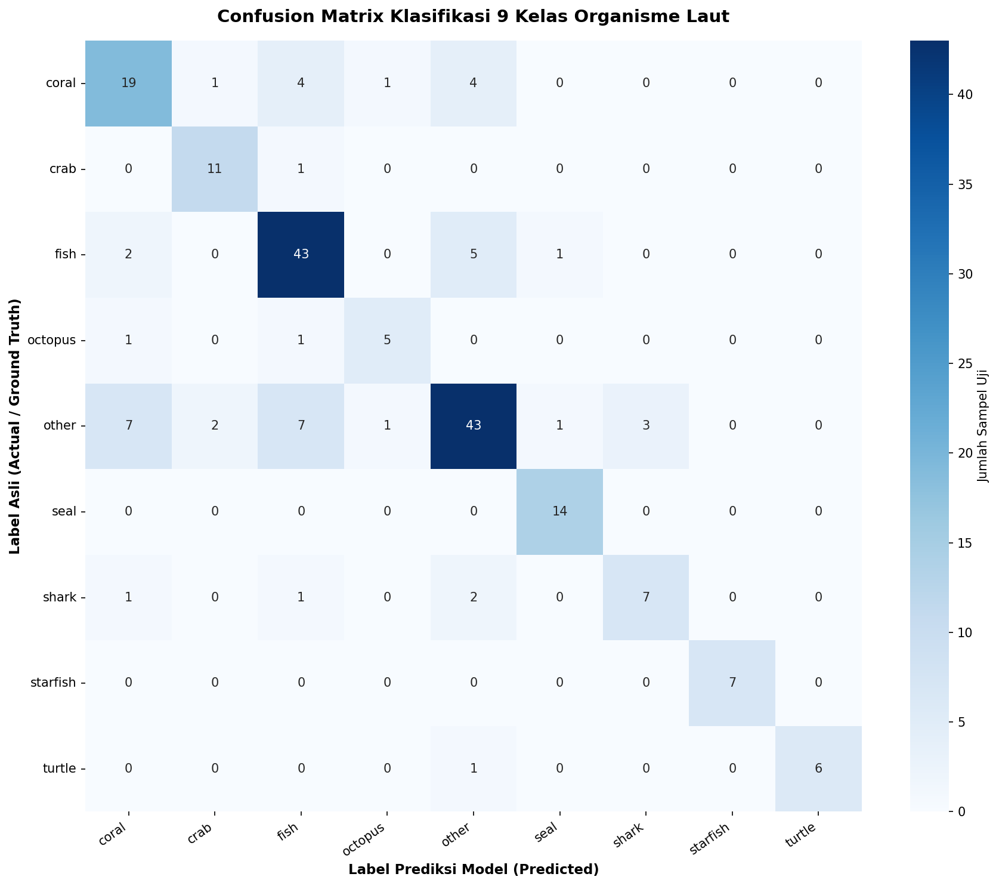

In [15]:
# 6.1 Visualisasi Confusion Matrix (Semua Kelas)
cm = confusion_matrix(y_true, y_pred, labels= list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(12, 10), dpi=150)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
    cbar_kws={"label": "Jumlah Sampel Uji"}, ax=ax
)
ax.set_title(f"Confusion Matrix Klasifikasi {NUM_CLASSES} Kelas Organisme Laut", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Label Prediksi Model (Predicted)", fontsize=11, fontweight="bold")
ax.set_ylabel("Label Asli (Actual / Ground Truth)", fontsize=11, fontweight="bold")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "confusion_matrix.png", dpi=150)
plt.show()

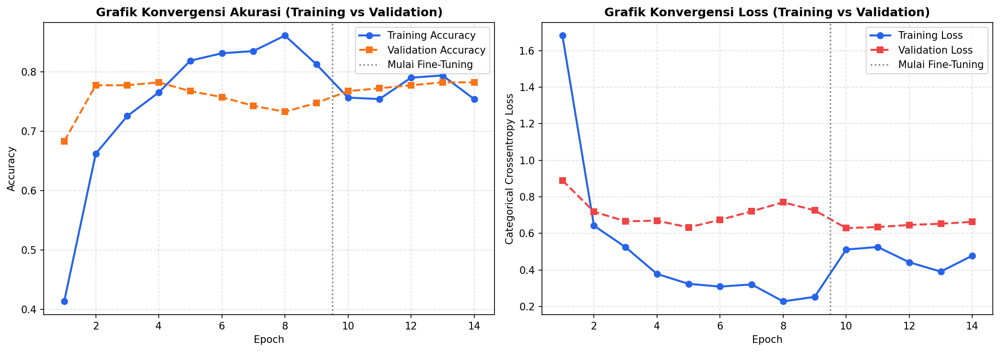

In [16]:
# 6.2 Grafik Akurasi dan Loss Selama Proses Pelatihan (Melihat Konvergensi Model)
epochs_range = range(1, len(history_dict["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=150)

# Plot Accuracy
axes[0].plot(epochs_range, history_dict["accuracy"], "o-", label="Training Accuracy", color="#2563eb", linewidth=2)
axes[0].plot(epochs_range, history_dict["val_accuracy"], "s--", label="Validation Accuracy", color="#f97316", linewidth=2)
if 0 < FINETUNE_START < len(epochs_range):
    axes[0].axvline(FINETUNE_START + 0.5, color="gray", linestyle=":", label="Mulai Fine-Tuning")
axes[0].set_title("Grafik Konvergensi Akurasi (Training vs Validation)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Plot Loss
axes[1].plot(epochs_range, history_dict["loss"], "o-", label="Training Loss", color="#2563eb", linewidth=2)
axes[1].plot(epochs_range, history_dict["val_loss"], "s--", label="Validation Loss", color="#ef4444", linewidth=2)
if 0 < FINETUNE_START < len(epochs_range):
    axes[1].axvline(FINETUNE_START + 0.5, color="gray", linestyle=":", label="Mulai Fine-Tuning")
axes[1].set_title("Grafik Konvergensi Loss (Training vs Validation)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Categorical Crossentropy Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "kurva_training.png", dpi=150)
plt.show()

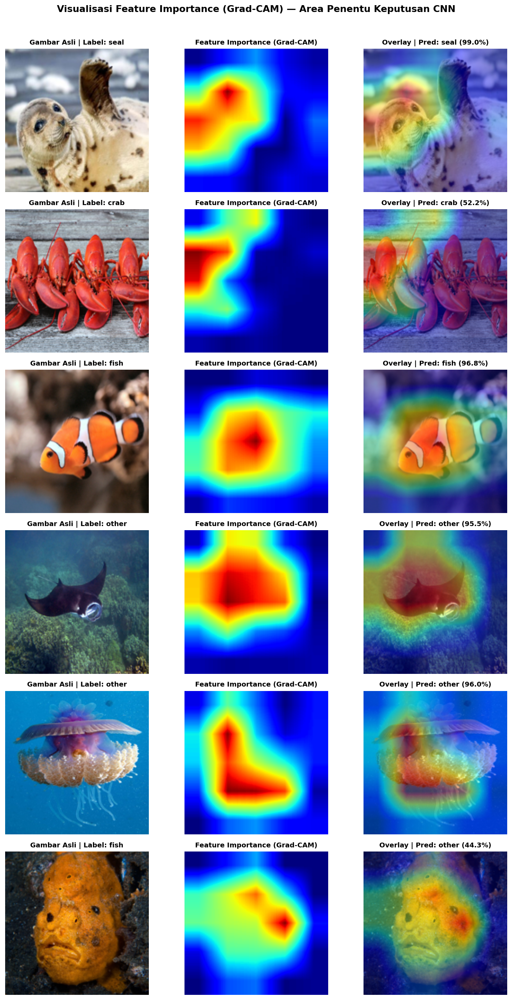

In [17]:
# 6.3 Visualisasi Feature Importance Menggunakan Grad-CAM (Area yang Memengaruhi Keputusan Model)
# Grad-CAM asli: gradien skor kelas terhadap feature map konvolusi terakhir (layer 'out_relu'), metode yang sama dengan app.py
def make_gradcam(img_array, class_index=None):
    grad_model = tf.keras.Model(model.inputs, [model.get_layer("out_relu").output, model.output])
    x = tf.convert_to_tensor(img_array[np.newaxis, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x, training=False)
        if class_index is None:
            class_index = int(tf.argmax(preds[0]))
        score = preds[:, class_index]
    grads = tape.gradient(score, conv_out)
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2))
    heat = tf.squeeze(conv_out[0] @ pooled[..., tf.newaxis])
    heat = tf.maximum(heat, 0) / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy()

def resize_heatmap(heat):
    hm = Image.fromarray(np.uint8(255 * heat)).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.array(hm) / 255.0

sample_grad_indices = np.linspace(0, len(test_df) - 1, min(6, len(test_df)), dtype=int)
fig, axes = plt.subplots(len(sample_grad_indices), 3, figsize=(11, 3.2 * len(sample_grad_indices)), dpi=150)
if len(sample_grad_indices) == 1:
    axes = np.expand_dims(axes, axis=0)

for row_i, test_idx in enumerate(sample_grad_indices):
    row_data = test_df.iloc[test_idx]
    true_lbl = row_data["label"]
    pred_idx = int(y_pred[test_idx])
    pred_lbl = CLASS_NAMES[pred_idx]
    conf_val = float(np.max(y_prob[test_idx])) * 100

    with Image.open(row_data["filepath"]) as im:
        im_resized = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
        img_np = np.array(im_resized, dtype=np.float32) / 255.0

    heatmap = resize_heatmap(make_gradcam(img_np, pred_idx))
    jet_color = plt.cm.jet(heatmap)[..., :3]
    overlay = np.clip(0.55 * img_np + 0.45 * jet_color, 0, 1)

    axes[row_i, 0].imshow(img_np)
    axes[row_i, 0].set_title(f"Gambar Asli | Label: {true_lbl}", fontsize=9.5, fontweight="bold")
    axes[row_i, 0].axis("off")

    axes[row_i, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[row_i, 1].set_title("Feature Importance (Grad-CAM)", fontsize=9.5, fontweight="bold")
    axes[row_i, 1].axis("off")

    axes[row_i, 2].imshow(overlay)
    axes[row_i, 2].set_title(f"Overlay | Pred: {pred_lbl} ({conf_val:.1f}%)", fontsize=9.5, fontweight="bold")
    axes[row_i, 2].axis("off")

plt.suptitle("Visualisasi Feature Importance (Grad-CAM) — Area Penentu Keputusan CNN", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "gradcam.png", dpi=150, bbox_inches="tight")
plt.show()


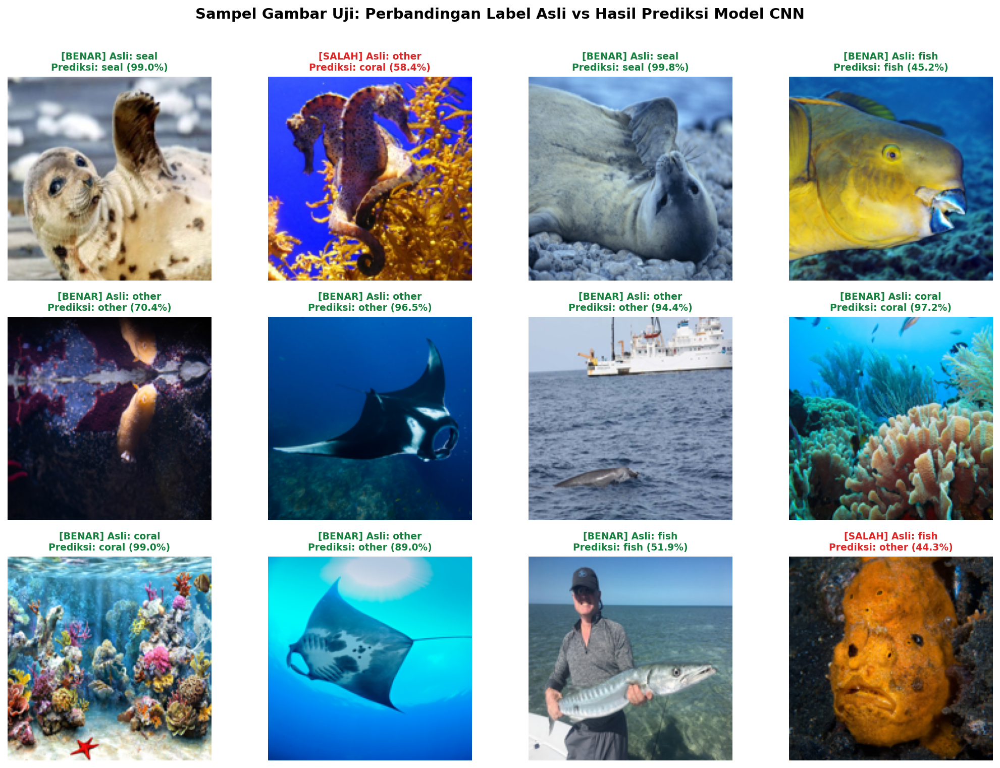

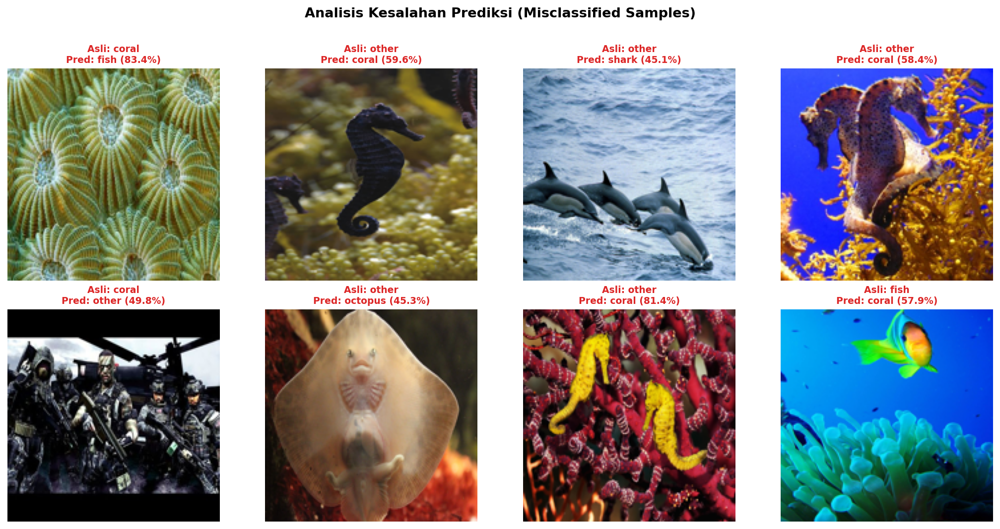

In [18]:
# 6.4 Contoh Gambar Uji Beserta Hasil Prediksi Model dan Label Aslinya
n_samples_grid = min(12, len(test_df))
grid_indices = np.linspace(0, len(test_df) - 1, n_samples_grid, dtype=int)

fig, axes = plt.subplots(3, 4, figsize=(14, 10), dpi=150)
axes = axes.flatten()

for i, idx_val in enumerate(grid_indices):
    row_data = test_df.iloc[idx_val]
    true_lbl = row_data["label"]
    pred_lbl = CLASS_NAMES[y_pred[idx_val]]
    conf_val = float(np.max(y_prob[idx_val])) * 100
    is_correct = (true_lbl == pred_lbl)

    with Image.open(row_data["filepath"]) as im:
        axes[i].imshow(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
    status_txt = "BENAR" if is_correct else "SALAH"
    title_color = "#15803d" if is_correct else "#dc2626"
    axes[i].set_title(
        f"[{status_txt}] Asli: {true_lbl}\nPrediksi: {pred_lbl} ({conf_val:.1f}%)",
        fontsize=9, fontweight="bold", color=title_color
    )
    axes[i].axis("off")

for j in range(n_samples_grid, len(axes)):
    axes[j].axis("off")

plt.suptitle("Sampel Gambar Uji: Perbandingan Label Asli vs Hasil Prediksi Model CNN", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "prediksi_contoh.png", dpi=150, bbox_inches="tight")
plt.show()

# Simpan juga khusus sampel yang salah diprediksi (untuk evaluasi mendalam di Streamlit)
wrong_indices = np.where(y_true != y_pred)[0]
if len(wrong_indices) > 0:
    n_wrong = min(8, len(wrong_indices))
    fig, axes = plt.subplots(2, 4, figsize=(14, 7), dpi=150)
    axes = axes.flatten()
    for i, w_idx in enumerate(wrong_indices[:n_wrong]):
        row_data = test_df.iloc[w_idx]
        true_lbl = row_data["label"]
        pred_lbl = CLASS_NAMES[y_pred[w_idx]]
        conf_val = float(np.max(y_prob[w_idx])) * 100
        with Image.open(row_data["filepath"]) as im:
            axes[i].imshow(im.convert("RGB").resize((IMG_SIZE, IMG_SIZE)))
        axes[i].set_title(f"Asli: {true_lbl}\nPred: {pred_lbl} ({conf_val:.1f}%)", fontsize=9, fontweight="bold", color="#dc2626")
        axes[i].axis("off")
    for j in range(n_wrong, len(axes)):
        axes[j].axis("off")
    plt.suptitle("Analisis Kesalahan Prediksi (Misclassified Samples)", fontsize=13, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(ARTIFACTS_DIR / "prediksi_salah.png", dpi=150, bbox_inches="tight")
    plt.show()

---
## Langkah 7 — Penyimpanan Metadata & Analisis Lengkap untuk Dashboard Streamlit (`app.py`)
Menyimpan seluruh metrik, parameter model, ringkasan dataset (80% Train : 20% Validation/Test), dan analisis naratif dari setiap grafik ke dalam `artifacts/meta.json` untuk ditampilkan oleh aplikasi `app.py`.

In [19]:
# Susun pasangan kelas yang paling sering tertukar di Confusion Matrix
cm_off_diag = cm.copy()
np.fill_diagonal(cm_off_diag, 0)
most_confused_pairs = []
for _ in range(3):
    if cm_off_diag.max() == 0:
        break
    r_idx, c_idx = np.unravel_index(np.argmax(cm_off_diag), cm_off_diag.shape)
    most_confused_pairs.append(f"{CLASS_NAMES[r_idx]} -> {CLASS_NAMES[c_idx]} ({int(cm_off_diag[r_idx, c_idx])} sampel)")
    cm_off_diag[r_idx, c_idx] = 0

gap_last = (history_dict['accuracy'][-1] - history_dict['val_accuracy'][-1]) * 100
n_correct_grid = int(sum(test_df.iloc[i]["label"] == CLASS_NAMES[y_pred[i]] for i in grid_indices))

meta_payload = {
    "project_title": f"Klasifikasi {NUM_CLASSES} Kelas Organisme Laut (Oceanic Life) Menggunakan CNN",
    "label_mode": LABEL_MODE,
    "arch_mode": model.name,
    "num_classes": NUM_CLASSES,
    "classes": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "channels": CHANNELS,
    "optimizer": OPTIMIZER_NAME,
    "learning_rate": LEARNING_RATE,
    "fine_tune_lr": FINE_TUNE_LR,
    "batch_size": BATCH_SIZE,
    "epochs_trained": len(history_dict["accuracy"]),
    "raw_total_files": len(all_files),
    "corrupt_removed": len(corrupt_files),
    "duplicates_removed": len(duplicate_files),
    "clean_total_images": len(df_data),
    "split_ratio": "80% Training : 20% Validation/Test",
    "n_train": int(len(train_df)),
    "n_val": int(len(val_df)),
    "n_test": int(len(test_df)),
    "train_pct": round(len(train_df) / len(df_data) * 100, 1),
    "test_pct": round(len(test_df) / len(df_data) * 100, 1),
    "class_counts": {k: int(v) for k, v in class_counts.items()},
    "imbalance_ratio": imbalance_ratio,
    "width_range": [int(min(widths)), int(max(widths))],
    "height_range": [int(min(heights)), int(max(heights))],
    "color_modes": {k: int(v) for k, v in mode_counts.items()},
    "metrics": {
        "accuracy": round(acc, 4),
        "precision_macro": round(prec_macro, 4),
        "recall_macro": round(rec_macro, 4),
        "f1_macro": round(f1_macro, 4),
        "precision_weighted": round(prec_weighted, 4),
        "recall_weighted": round(rec_weighted, 4),
        "f1_weighted": round(f1_weighted, 4)
    },
    "per_class": per_class_rows,
    "history": history_dict,
    "analisis": {
        "distribusi": (
            f"Dari total {len(all_files)} file mentah, ditemukan {len(corrupt_files)} file rusak dan {len(duplicate_files)} duplikat identik (MD5), "
            f"sehingga tersisa {len(df_data)} gambar unik yang tersebar di {NUM_CLASSES} kelas organisme laut. "
            f"Kelas dengan sampel terbanyak adalah '{max_cls}' ({max_val} gambar), sedangkan kelas tersedikit adalah '{min_cls}' ({min_val} gambar) "
            f"dengan rasio ketidakseimbangan {imbalance_ratio}:1. Ketidakseimbangan ini telah ditangani menggunakan Stratified Split (80% Train : 20% Test/Val) dan Class Weighting."
        ),
        "contoh_gambar": (
            f"Visualisasi sampel dari ke-{NUM_CLASSES} kelas menunjukkan variasi pencahayaan bawah air (dominasi spektrum biru-hijau), "
            f"perbedaan skala objek, serta kemiripan tekstur latar belakang terumbu karang. Oleh karena itu dilakukan normalisasi piksel [0, 1] dan augmentasi rotasi/flip/zoom."
        ),
        "ukuran": (
            f"Resolusi asli gambar bervariasi antara lebar {min(widths)}–{max(widths)} piksel dan tinggi {min(heights)}–{max(heights)} piksel, "
            f"dengan distribusi format warna {dict(mode_counts)}. Seluruh gambar diseragamkan ke ukuran {IMG_SIZE}x{IMG_SIZE} piksel RGB agar dimensi input tensor CNN konsisten."
        ),
        "training": (
            f"Selama {len(history_dict['accuracy'])} epoch pelatihan, Training Accuracy meningkat hingga {history_dict['accuracy'][-1]*100:.2f}% "
            f"dan Validation Accuracy mencapai {history_dict['val_accuracy'][-1]*100:.2f}%. Penurunan kurva Training Loss ({history_dict['loss'][-1]:.4f}) "
            f"dan Validation Loss ({history_dict['val_loss'][-1]:.4f}) menunjukkan konvergensi model. Selisih akurasi latih dan validasi pada epoch terakhir adalah {gap_last:.2f} poin persentase "
            f"({'indikasi overfitting' if gap_last > 10 else 'generalisasi relatif baik'})."
        ),
        "confusion_matrix": (
            f"Confusion Matrix memperlihatkan konsentrasi nilai tinggi pada diagonal utama yang menandakan mayoritas prediksi tepat sasaran. "
            f"Pasangan kelas yang paling sering tertukar adalah: {', '.join(most_confused_pairs) if most_confused_pairs else 'tidak ada kesalahan dominan'}, "
            f"yang kemungkinan dipengaruhi oleh kemiripan siluet tubuh di perairan terbuka maupun latar terumbu karang."
        ),
        "evaluasi": (
            f"Model meraih Accuracy {acc*100:.2f}%, Precision (Macro) {prec_macro*100:.2f}%, Recall (Macro) {rec_macro*100:.2f}%, "
            f"dan F1-Score (Macro) {f1_macro*100:.2f}% (Weighted F1: {f1_weighted*100:.2f}%). "
            f"F1-Score macro mencerminkan keseimbangan antara presisi dan sensitivitas model. "
            f"Kelas yang paling mudah dikenali adalah '{best_cls}' (F1: {best_row['f1-score']*100:.1f}%), "
            f"sedangkan kelas tersulit adalah '{worst_cls}' (F1: {worst_row['f1-score']*100:.1f}%)."
        ),
        "gradcam": (
            "Visualisasi Feature Importance menggunakan Grad-CAM menandai area gambar yang paling memengaruhi keputusan jaringan konvolusi (CNN) "
            "(merah = pengaruh tinggi). Jika area merah berada pada tubuh organisme, model belajar dari fitur yang tepat; jika berada pada latar belakang, model berpotensi mengandalkan konteks seperti warna air."
        ),
        "prediksi": (
            f"Dari {n_samples_grid} gambar uji yang ditampilkan, {n_correct_grid} diprediksi benar. "
            f"Kesalahan prediksi dapat terjadi pada gambar dengan objek berukuran sangat kecil, terhalang bayangan bawah air, atau memiliki lebih dari satu biota laut dalam satu frame."
        )
    }
}

with open(ARTIFACTS_DIR / "meta.json", "w", encoding="utf-8") as f:
    json.dump(meta_payload, f, indent=2, ensure_ascii=False)

# Siapkan dan simpan eval_data.pkl agar kompatibel 100% dengan dashboard Streamlit (app.py)
sp_df = pd.DataFrame({
    "Train": train_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0),
    "Val": val_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0),
    "Test": test_df["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)
}, index=CLASS_NAMES)

eval_data = {
    "class_names": CLASS_NAMES,
    "img_size": IMG_SIZE,
    "history": history_dict,
    "cm": cm,
    "per_class_df": df_per_class,
    "metrics_df": df_metrics,
    "split_info": {
        "n_train": int(len(train_df)),
        "n_val": int(len(val_df)),
        "n_test": int(len(test_df)),
        "per_class": sp_df
    },
    "class_counts": class_counts,
    "imbalance_ratio": float(imbalance_ratio),
    "class_weight_used": True,
    "finetune_start": FINETUNE_START,
    "val_equals_test": True,
    "label_source": LABEL_MODE,
    "sanity_warnings": [],
    "img_stats": {
        "modes": dict(mode_counts),
        "n_sampled": len(widths),
        "width_min": int(min(widths)) if widths else 0,
        "width_max": int(max(widths)) if widths else 0,
        "width_median": float(np.median(widths)) if widths else 0.0,
        "height_min": int(min(heights)) if heights else 0,
        "height_max": int(max(heights)) if heights else 0,
        "height_median": float(np.median(heights)) if heights else 0.0,
        "n_corrupt": len(corrupt_files),
        "n_duplicate": len(duplicate_files),
        "n_skipped_format": 0
    },
    "hyperparams": {
        "Arsitektur Model": model.name,
        "Ukuran Gambar Input": f"{IMG_SIZE}x{IMG_SIZE} px (3 channel RGB)",
        "Optimizer": OPTIMIZER_NAME,
        "Initial Learning Rate": LEARNING_RATE,
        "Fine-Tune Learning Rate": FINE_TUNE_LR if (base_model is not None and EPOCHS_PHASE_2 > 0) else "N/A",
        "Batch Size": BATCH_SIZE,
        "Total Epochs": len(history_dict["accuracy"]),
        "Loss Function": "Categorical Crossentropy",
        "Activation Hidden Layer": "ReLU",
        "Activation Output Layer": f"Softmax ({NUM_CLASSES} kelas)",
        "Sumber Label": "CLIP zero-shot (pseudo-label)",
        "Ambang Keyakinan CLIP": CONF_THRESHOLD,
        "Gambar Dibuang (Keyakinan CLIP Rendah)": N_LOW_CONF,
        "Gambar Masuk Kelas Other": N_OTHER
    },
    "baseline_acc": float(class_counts.max() / max(total_clean, 1)),
    "pred_sample_summary": {
        "n_shown": int(n_samples_grid),
        "n_correct": int(sum(test_df.iloc[idx_val]["label"] == CLASS_NAMES[y_pred[idx_val]] for idx_val in grid_indices))
    }
}

with open(ARTIFACTS_DIR / "eval_data.pkl", "wb") as f:
    pickle.dump(eval_data, f)

print(f"[SUKSES] File artefak 'meta.json' dan 'eval_data.pkl' berhasil disimpan di: {ARTIFACTS_DIR.resolve()}")
print("[INFO] Anda kini dapat menjalankan dashboard Streamlit: streamlit run app.py")

[SUKSES] File artefak 'meta.json' dan 'eval_data.pkl' berhasil disimpan di: C:\test 2 Klasifikasi CNN\artifacts
[INFO] Anda kini dapat menjalankan dashboard Streamlit: streamlit run app.py
